# Week 1: Polynomial and Interaction Terms
**Rupal Paliwal, Mod C, Semester 1**

**Dataset:** Movies Box Office 2000 to 2024 (Kaggle), 5,000 top grossing films (the top 200 of each year). This is the primary dataset from my capstone proposal (*Movie Consumer Behavior & Film Profitability Analysis*).

**Question:** Is the relationship between a film's features and its worldwide revenue really a straight line? Do squared terms or interaction terms help, and do they create multicollinearity?

**Part 1** uses the box office data. **Part 2** adds the other two project datasets, MovieLens 20M and the 4 Services Streaming catalogs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

## 1. Load and prepare the data

Same preparation as Weeks 2 and 4: rating converted from text like `'8.217/10'`, vote count logged, genres as 0/1 columns, the top 10 languages as 0/1 columns (English is the reference), and rows with missing or zero ratings dropped. The money columns other than the target are left out because worldwide gross is domestic plus foreign, so they would leak the answer.

**Target:** `log($Worldwide)`, because revenue is heavily right skewed.

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')

data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

# Numeric features
X = pd.DataFrame({
    'log_votes': np.log1p(data['Vote_Count']),
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

# Genres (multi hot) and top 10 languages (English is the reference)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
y = np.log(data['$Worldwide'])
print('Rows:', X.shape[0], '| Features:', X.shape[1])

Rows: 4803 | Features: 32


## 2. Train/test split and a baseline

I hold out 20% of films as a test set and only look at it at the end. All model choices are made with 5 fold cross validation (CV) on the training set, which is the main protection against overfitting this week.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def score(name, Xtr, Xte):
    model = make_pipeline(StandardScaler(), LinearRegression())
    cv = cross_val_score(model, Xtr, y_train, cv=kf, scoring='r2').mean()
    test = r2_score(y_test, model.fit(Xtr, y_train).predict(Xte))
    return {'model': name, 'features': Xtr.shape[1], 'CV_R2': round(cv, 4), 'test_R2': round(test, 4)}

results = [score('Linear (no extra terms)', X_train, X_test)]
pd.DataFrame(results)

,model,features,CV_R2,test_R2
0,Linear (no extra terms),32,0.5468,0.5256


## 3. Polynomial terms for vote count

Vote count is the strongest predictor from earlier weeks. I fit log revenue on log votes alone with polynomials of degree 1 to 6 and let CV pick the degree. A very high degree would overfit (big wiggles between points), so CV should stop improving at some point.

In [4]:
rows = []
for d in range(1, 7):
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    cv = cross_val_score(model, X_train[['log_votes']], y_train, cv=kf, scoring='r2').mean()
    rows.append({'degree': d, 'CV_R2': round(cv, 4)})
pd.DataFrame(rows)

,degree,CV_R2
0,1,0.3981
1,2,0.5125
2,3,0.5226
3,4,0.5260
4,5,0.5270
5,6,0.5252


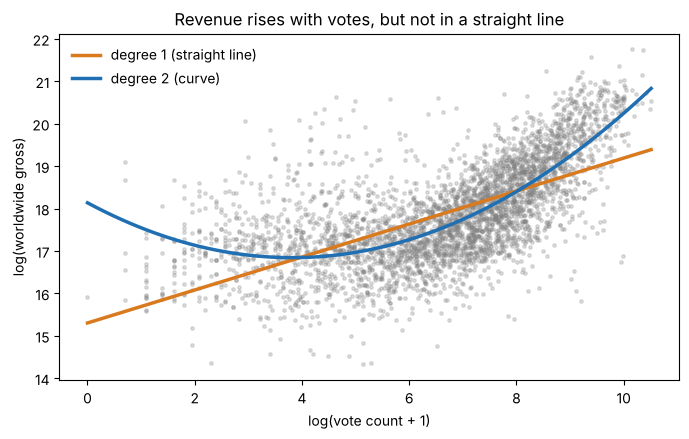

In [5]:
xs = np.linspace(X_train['log_votes'].min(), X_train['log_votes'].max(), 200).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.scatter(X_train['log_votes'], y_train, s=6, alpha=0.25, color='grey')
for d, color in [(1, '#d97a1f'), (2, '#1f6fb2')]:
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(X_train[['log_votes']], y_train)
    plt.plot(xs, m.predict(pd.DataFrame(xs, columns=['log_votes'])), color=color, linewidth=2.5,
             label='degree 1 (straight line)' if d == 1 else 'degree 2 (curve)')
plt.xlabel('log(vote count + 1)')
plt.ylabel('log(worldwide gross)')
plt.title('Revenue rises with votes, but not in a straight line')
plt.legend(frameon=False)
plt.show()

Degree 2 gives by far the biggest jump in CV R². Degrees 3 to 5 add only about 0.01 more, and degree 6 starts to drop, which is the first sign of overfitting. I use **degree 2** as the reasonable choice.

The straight line misses the shape badly. The curve rises steeply on the right, and on the far left it bends back up because films with the fewest votes earn more than a straight line predicts. Section 7 shows that many of those films are non English, which matches my Module B finding that a large group of films earn mostly outside the U.S.

## 4. A squared term for year (EDA connection)

In my Module B EDA, median revenue rose from 2000 to the mid 2010s, then crashed in 2020 (COVID) and only partly recovered. A straight line in `year` can't describe a rise and then a fall, but an inverted parabola (negative `year²` term) can, which is exactly the lesson's example.

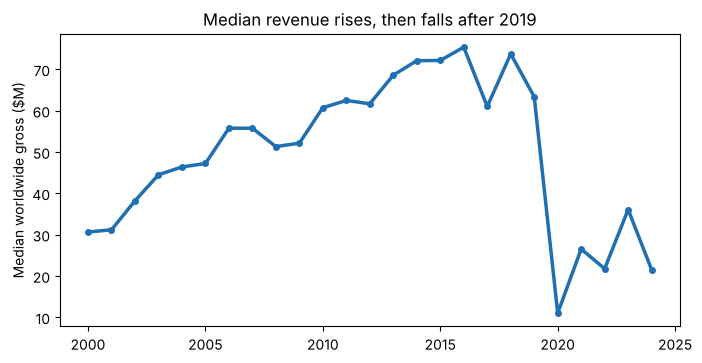

In [6]:
median_by_year = df.groupby('Year')['$Worldwide'].median() / 1e6
plt.figure(figsize=(8, 3.8))
plt.plot(median_by_year.index, median_by_year.values, color='#1f6fb2', linewidth=2.5, marker='o', markersize=4)
plt.ylabel('Median worldwide gross ($M)')
plt.title('Median revenue rises, then falls after 2019')
plt.show()

## 5. Add squared terms to the full model

I add squares of the three numeric features (log votes, rating, year). The genre and language columns are 0/1, so squaring them would change nothing.

Each numeric feature is **centered** (training mean subtracted) before squaring. Section 6 shows why.

In [7]:
num = ['log_votes', 'rating', 'year']
means = X_train[num].mean()   # training means only, so no test information leaks in

def add_squares(Z):
    Z = Z.copy()
    for c in num:
        Z[c + '_sq'] = (Z[c] - means[c]) ** 2
    return Z

results.append(score('+ squared terms', add_squares(X_train), add_squares(X_test)))
pd.DataFrame(results)

,model,features,CV_R2,test_R2
0,Linear (no extra terms),32,0.5468,0.5256
1,+ squared terms,35,0.6250,0.6172


## 6. Multicollinearity check with VIF

Squared terms are a classic source of multicollinearity. Year only runs from 2000 to 2024, a narrow range far from zero, so `year` and `year²` move almost in lockstep. A variance inflation factor (VIF) above 5 signals a problem.

In [8]:
def vif_table(Z):
    Z = sm.add_constant(Z.astype(float))
    return pd.Series([variance_inflation_factor(Z.values, i) for i in range(1, Z.shape[1])],
                     index=Z.columns[1:]).round(1)

raw = X_train[num].copy()
raw['log_votes_sq'] = raw['log_votes'] ** 2
raw['year_sq'] = raw['year'] ** 2

centered = X_train[num].copy()
centered['log_votes_sq'] = (centered['log_votes'] - means['log_votes']) ** 2
centered['year_sq'] = (centered['year'] - means['year']) ** 2

pd.DataFrame({'VIF raw squares': vif_table(raw), 'VIF centered squares': vif_table(centered)})

,VIF raw squares,VIF centered squares
log_votes,28.4,1.5
rating,1.2,1.2
year,416829.5,1.1
log_votes_sq,28.6,1.3
year_sq,416887.3,1.1


Raw `year` and `year²` have VIFs in the hundreds of thousands, and log votes with its square is well above 5. After centering, every VIF drops to about 1. Centering doesn't change the model's predictions, but it makes the coefficients stable and readable.

I also checked the VIFs of all 32 original features, since the lesson says a VIF catches collinearity that pairwise correlations can miss:

In [9]:
vif_table(X_train).sort_values(ascending=False).head(6)

log_votes          2.9
lang_ja            2.0
genre_Family       1.8
genre_Animation    1.8
genre_Drama        1.7
rating             1.7
dtype: float64

All are below 3, so the original features don't have a multicollinearity problem.

## 7. Interaction term: votes × English

Earlier weeks suggested that TMDB vote counts may mean something different for English and non English films. An interaction term lets the slope of revenue on votes depend on language. First, a picture: one regression line per group.

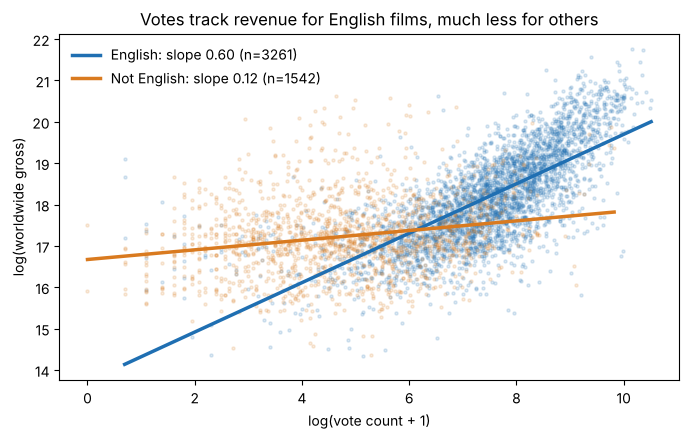

In [10]:
english = (data['Original_Language'] == 'en')
plt.figure(figsize=(8, 4.5))
for mask, color, label in [(english, '#1f6fb2', 'English'), (~english, '#d97a1f', 'Not English')]:
    xv, yv = X.loc[mask, 'log_votes'], y[mask]
    plt.scatter(xv, yv, s=5, alpha=0.15, color=color)
    b1, b0 = np.polyfit(xv, yv, 1)
    grid = np.linspace(xv.min(), xv.max(), 100)
    plt.plot(grid, b0 + b1 * grid, color=color, linewidth=2.5, label=f'{label}: slope {b1:.2f} (n={mask.sum()})')
plt.xlabel('log(vote count + 1)')
plt.ylabel('log(worldwide gross)')
plt.title('Votes track revenue for English films, much less for others')
plt.legend(frameon=False)
plt.show()

The slopes are very different. For English films, more votes means much more revenue. For non English films, the line is almost flat. Now I add `log_votes × english` (centered) to the model with squared terms.

In [11]:
def add_interaction(Z):
    Z = add_squares(Z)
    is_english = (Z.filter(like='lang_').sum(axis=1) == 0).astype(int)
    Z['votes_x_english'] = (Z['log_votes'] - means['log_votes']) * is_english
    return Z

results.append(score('+ squared terms + interaction', add_interaction(X_train), add_interaction(X_test)))
pd.DataFrame(results)

,model,features,CV_R2,test_R2
0,Linear (no extra terms),32,0.5468,0.5256
1,+ squared terms,35,0.6250,0.6172
2,+ squared terms + interaction,36,0.6246,0.6179


## 8. Which new terms are significant?

statsmodels gives p values for the final model (on the training set).

In [12]:
ols = sm.OLS(y_train, sm.add_constant(add_interaction(X_train).astype(float))).fit()
terms = ['log_votes', 'log_votes_sq', 'rating', 'rating_sq', 'year', 'year_sq', 'votes_x_english']
pd.DataFrame({'coef': ols.params[terms], 'p_value': ols.pvalues[terms]}).round(4)

,coef,p_value
log_votes,0.5211,0.0000
log_votes_sq,0.0719,0.0000
rating,-0.1494,0.0000
rating_sq,-0.0659,0.0000
year,0.0015,0.4147
year_sq,-0.0014,0.0000
votes_x_english,0.0707,0.0024


# Part 2: All Three Project Datasets

My project has three datasets: the box office data used above, **MovieLens 20M** (user ratings, tags, and the tag genome), and the **4 Services Streaming** catalogs (Netflix, Prime Video, Hulu, Disney+). `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb` joins them by cleaned title and release year and saves `combined_films.csv`.

MovieLens 20M ends in 2015, so Part 2 uses the **films released 2000 to 2015 that matched MovieLens**. To see what the extra datasets add, every model is fit twice on exactly the same films and split:
- **Box office only**: the same 32 features as Part 1
- **All three datasets**: those 32 plus 7 new ones: MovieLens rating count (log), MovieLens average rating, MovieLens tag count (log), and 0/1 flags for Netflix, Prime Video, Hulu, and Disney+

In [13]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = np.log(sub['$Worldwide'])                     # log worldwide gross
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


## P2.1 Three overlapping measures of audience reach

TMDB vote count, MovieLens rating count, and MovieLens tag count all measure roughly the same thing (how many people engaged with a film), so they could be collinear. I check correlations and VIFs before adding squared terms.

In [14]:
aud = ['log_votes', 'ml_log_ratings', 'ml_log_tags', 'rating', 'ml_mean_rating', 'year']
print(XB[aud].corr().round(2))
vif_table(XB[aud])

                log_votes  ml_log_ratings  ml_log_tags  rating  \
log_votes            1.00            0.55         0.70    0.39   
ml_log_ratings       0.55            1.00         0.77    0.27   
ml_log_tags          0.70            0.77         1.00    0.46   
rating               0.39            0.27         0.46    1.00   
ml_mean_rating       0.27            0.30         0.51    0.78   
year                 0.28           -0.48        -0.02    0.08   

                ml_mean_rating  year  
log_votes                 0.27  0.28  
ml_log_ratings            0.30 -0.48  
ml_log_tags               0.51 -0.02  
rating                    0.78  0.08  
ml_mean_rating            1.00  0.09  
year                      0.09  1.00  


log_votes         3.8
ml_log_ratings    7.6
ml_log_tags       4.9
rating            3.0
ml_mean_rating    3.3
year              3.8
dtype: float64

## P2.2 Squared terms with and without the extra datasets

In [15]:
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42)

def score3(name, Z):
    model = make_pipeline(StandardScaler(), LinearRegression())
    cv = cross_val_score(model, Z.loc[tr3], y3[tr3], cv=kf, scoring='r2').mean()
    test = r2_score(y3[te3], model.fit(Z.loc[tr3], y3[tr3]).predict(Z.loc[te3]))
    return {'model': name, 'features': Z.shape[1], 'CV_R2': round(cv, 4), 'test_R2': round(test, 4)}

def add_squares3(Z):
    Z = Z.copy()
    for col in [c for c in ['log_votes', 'rating', 'year', 'ml_log_ratings', 'ml_mean_rating'] if c in Z]:
        Z[col + '_sq'] = (Z[col] - Z.loc[tr3, col].mean()) ** 2
    return Z

pd.DataFrame([score3('Box office only, linear', XA),
              score3('Box office only, + squared terms', add_squares3(XA)),
              score3('All three datasets, linear', XB),
              score3('All three datasets, + squared terms', add_squares3(XB))])

,model,features,CV_R2,test_R2
0,"Box office only, linear",32,0.6312,0.6361
1,"Box office only, + squared terms",35,0.6974,0.6974
2,"All three datasets, linear",39,0.6371,0.6593
3,"All three datasets, + squared terms",44,0.7293,0.7438


## 9. Conclusions

**Squared terms helped a lot.** Adding just three centered squared terms (log votes, rating, year) raised test R² from **0.526 to 0.617**, and CV R² from 0.547 to 0.625. That is the biggest single improvement of any change I have made to this model. The plain linear model was **underfitting**: the relationship between votes and revenue is curved, not straight.

**The year effect is an inverted parabola.** The linear `year` term is not significant (p = 0.41), but `year²` is negative and highly significant. Revenue in this dataset rose into the mid 2010s and then fell after 2019, which a straight line can't capture. This came directly from my EDA.

**The interaction is real but redundant.** Votes predict revenue much more strongly for English films (slope 0.60) than for non English films (slope 0.12), and the interaction term is significant (p = 0.002). But it adds almost nothing to test R² (0.617 to 0.618) once the squared terms are in. Non English films sit mostly at low vote counts, so the curved vote term was already capturing most of their flatter slope.

**Multicollinearity was created and then fixed.** Raw `year` and `year²` had VIFs above 400,000, and log votes with its square about 28. Centering before squaring brought every VIF to about 1.5 or below, without changing predictions.

**How I avoided overfitting:** the polynomial degree was chosen by 5 fold CV (degree 6 already scored lower than degree 5), I only squared the 3 numeric features, and the test set was used only once at the end. Test R² stayed close to CV R² for every model, so these models are not overfitting.

**Part 2 (all three datasets).** The three reach measures are related (MovieLens rating count and tag count correlate at 0.77) but no VIF exceeds 10, so they can share a model. On the 2000 to 2015 films, squared terms still help, and the MovieLens and streaming features help on top of them; the table in P2.2 shows both effects. The best model uses all three datasets plus squared terms.

### Think About It

- **Why do interaction terms require a large sample size?** The model has to see a range of vote counts *within each language group* to estimate how the slope changes between groups, not just one overall slope. Here the non English group had 1,542 films, which was enough to make the interaction significant but not enough for it to improve predictions.
- **When do polynomial terms tend to produce multicollinearity?** When a feature's range is narrow compared to its distance from zero. Year (2000 to 2024) is the perfect example: `year` and `year²` are almost a straight line of each other (VIF above 400,000). Centering the feature first fixes it.
- **Why use a VIF instead of correlation?** A VIF catches collinearity that comes from a combination of features. In my dataset, worldwide gross is exactly domestic plus foreign gross. No single pair is perfectly correlated, but the VIF of worldwide gross would be infinite.
- **Why use correlation instead of a VIF?** Correlation is quicker, works for any pair, and tells you *which* two features are related. A VIF only says a feature is explained by the others, not by which ones.